# Company A — Exploratory Data Analysis (EDA)

**Goal of this notebook:** understand Company A's customer data well enough to (1) define the business problem, (2) decide how to prepare the data for modelling, and (3) collect evidence that will appear on the proposal slides.

Each section follows the same rhythm:

1. **Why** we are looking at something (the question).
2. **Code** that answers it.
3. **What we see** and **what it means for the business / the model**.

| # | Section | Question it answers |
|---|---|---|
| 1 | Setup | — |
| 2 | Load & merge | Do the two files fit together cleanly? |
| 3 | Column families | What are the ~100 columns actually about? |
| 4 | Target variable | How is `churn` distributed, and is it realistic? |
| 5 | Data quality | What is missing, impossible, skewed or redundant? |
| 6 | Customer profile | What does a typical customer look like? |
| 7 | Churn drivers | Which behaviours and attributes go with leaving? |
| 8 | Signal ranking | Which single columns separate churners best? Any leakage? |
| 9 | Value at risk | How much revenue is attached to churners? |
| 10 | Summary | Findings, hypotheses, and decisions for modelling |

> **How to run:** from the project root, `./env/bin/jupyter lab` (the local conda env created for this project), then open this notebook. It expects the `telecom/` folder next to it.

## 1. Setup

Standard data stack only: `pandas`/`numpy` for tables, `matplotlib`/`seaborn` for charts, `scikit-learn` for one metric (ROC-AUC) in Section 8.

Two conventions used throughout so the charts are consistent and slide-ready:
- **Colours:** blue = stayed, orange = churned; the grey dashed line on churn-rate charts is the overall churn rate (the "average" any segment should be compared to).
- **Every chart is saved** to `figures/` so it can be dropped into the slides.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid", context="notebook")
STAY, CHURN, BASE = "#4C72B0", "#DD8452", "#7F7F7F"
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

DATA_DIR = Path("telecom")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.0 | numpy 2.5.4


## 2. Load and merge the two tables

**Why:** the data arrives as two files. Before anything else we must confirm they describe the *same* customers, one row each, so that joining them does not silently duplicate or drop people.

- `Record.csv` — the "phone bill + call log": monthly averages of charges, minutes, call outcomes, plus the `churn` label.
- `Client.csv` — the "customer profile": tenure, credit, handset, household, demographics.

In [2]:
record = pd.read_csv(DATA_DIR / "Record.csv")
client = pd.read_csv(DATA_DIR / "Client.csv")

print("Record:", record.shape, "| Client:", client.shape)
print("Unique IDs  -> Record:", record.Customer_ID.is_unique, "| Client:", client.Customer_ID.is_unique)
print("Same ID set :", set(record.Customer_ID) == set(client.Customer_ID))
print("Shared columns other than the ID:", (set(record.columns) & set(client.columns)) - {"Customer_ID"})

df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print("Merged:", df.shape)
df.head(3)

Record: (100000, 51) | Client: (100000, 50)
Unique IDs  -> Record: True | Client: True
Same ID set : True
Shared columns other than the ID: set()
Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.0,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.0,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.0,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0


**What we see:** 100,000 customers in each file, IDs are unique and identical across files, and the only shared column is the ID. `validate="one_to_one"` would raise an error if that were not true.

**Meaning:** a clean 1:1 join. The merged table has **100,000 rows × 100 columns** (98 features + `churn` + `Customer_ID`).

## 3. Column families — making ~100 columns manageable

**Why:** 100 columns is too many to reason about one by one. Using the data dictionary (`Company A Dataset Overview`), we group them into **families** that each answer one business question. We will refer to these families for the rest of the analysis.

Telecom shorthand used in names: `mou` = minutes of use, `vce` = voice, `dat` = data, `rev` = revenue, `mrc` = monthly recurring charge (the plan fee), `ovr` = overage (charges beyond the plan), `plcd` = placed (attempted), `comp` = completed, `drop` = cut off mid-call, `blck` = couldn't connect, `opk` = off-peak, `cc`/`custcare` = customer care.

In [3]:
FAMILIES = {
    "Money (monthly bill)": ["rev_Mean", "totmrc_Mean", "ovrrev_Mean", "vceovr_Mean", "datovr_Mean",
                             "change_rev", "da_Mean"],
    "Usage (minutes & calls)": ["mou_Mean", "change_mou", "ovrmou_Mean", "roam_Mean", "plcd_vce_Mean", "plcd_dat_Mean",
                                "recv_vce_Mean", "recv_sms_Mean", "comp_vce_Mean", "comp_dat_Mean", "inonemin_Mean",
                                "threeway_Mean", "mou_cvce_Mean", "mou_cdat_Mean", "mou_rvce_Mean", "owylis_vce_Mean",
                                "mouowylisv_Mean", "iwylis_vce_Mean", "mouiwylisv_Mean", "peak_vce_Mean",
                                "peak_dat_Mean", "mou_peav_Mean", "mou_pead_Mean", "opk_vce_Mean", "opk_dat_Mean",
                                "mou_opkv_Mean", "mou_opkd_Mean", "attempt_Mean", "complete_Mean",
                                "callfwdv_Mean", "callwait_Mean"],
    "Service quality": ["drop_vce_Mean", "drop_dat_Mean", "blck_vce_Mean", "blck_dat_Mean",
                        "unan_vce_Mean", "unan_dat_Mean", "drop_blk_Mean"],
    "Customer care": ["custcare_Mean", "ccrndmou_Mean", "cc_mou_Mean"],
    "Account & lifetime": ["months", "uniqsubs", "actvsubs", "crclscod", "asl_flag", "totcalls", "totmou", "totrev",
                           "adjrev", "adjmou", "adjqty", "avgrev", "avgmou", "avgqty", "avg3mou", "avg3qty",
                           "avg3rev", "avg6mou", "avg6qty", "avg6rev"],
    "Handset": ["eqpdays", "hnd_price", "refurb_new", "hnd_webcap", "dualband", "phones", "models", "new_cell"],
    "Geography & demographics": ["area", "prizm_social_one", "truck", "rv", "ownrent", "lor", "dwlltype", "marital",
                                 "adults", "infobase", "income", "numbcars", "HHstatin", "dwllsize", "forgntvl",
                                 "ethnic", "kid0_2", "kid3_5", "kid6_10", "kid11_15", "kid16_17", "creditcd"],
}
col2fam = {c: f for f, cols in FAMILIES.items() for c in cols}

# Sanity check: every feature belongs to exactly one family
features = [c for c in df.columns if c not in ("churn", "Customer_ID")]
assert set(features) == set(col2fam), set(features) ^ set(col2fam)

pd.Series({f: len(c) for f, c in FAMILIES.items()}, name="n_columns").to_frame()

,n_columns
Money (monthly bill),7
Usage (minutes & calls),31
Service quality,7
Customer care,3
Account & lifetime,20
Handset,8
Geography & demographics,22


**What we see:** almost a third of the columns (31) describe *usage*. Many of those are slices of the same thing (peak vs off-peak, placed vs completed). Section 5.5 measures how redundant they are.

**Meaning:** in the slides we can describe the data as **7 families** rather than 98 columns, which is easier for executives to follow.

### 3.1 Numbers vs text

**Why:** most ML models only accept numbers, so text (categorical) columns need encoding later. We also want to know how many distinct values each text column has (its *cardinality*). A column with a handful of levels can be one-hot encoded; one with dozens needs a different approach.

In [4]:
cat_cols = df[features].select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in features if c not in cat_cols]
print(f"{len(num_cols)} numeric | {len(cat_cols)} categorical")

card = pd.DataFrame({
    "family": [col2fam[c] for c in cat_cols],
    "n_levels": [df[c].nunique() for c in cat_cols],
    "levels (most common first)": [", ".join(map(str, df[c].value_counts().index[:8])) for c in cat_cols],
}, index=cat_cols).sort_values("n_levels", ascending=False)
card

77 numeric | 21 categorical


,family,n_levels,levels (most common first)
crclscod,Account & lifetime,54,"AA, A, BA, CA, EA, B, DA, ZA"
area,Geography & demographics,19,"NEW YORK CITY AREA, LOS ANGELES AREA, DC/MARYL..."
ethnic,Geography & demographics,17,"N, H, S, U, G, Z, O, I"
dwllsize,Geography & demographics,15,"A, B, C, J, O, N, D, K"
HHstatin,Geography & demographics,6,"C, I, A, B, G, H"
marital,Geography & demographics,5,"U, M, S, B, A"
prizm_social_one,Geography & demographics,5,"S, U, C, T, R"
dualband,Handset,4,"Y, N, T, U"
new_cell,Handset,3,"U, Y, N"
hnd_webcap,Handset,3,"WCMB, WC, UNKW"


**What we see:** 21 text columns. Most have 2–6 levels. Many use **`U` for "unknown"**, which is effectively a hidden missing value. Two have many levels: `crclscod` (credit class, 54 codes) and `area` (19 regions).

**Meaning for modelling:** use native categorical handling (LightGBM/CatBoost) or one-hot encoding rather than the tutorial's `LabelEncoder`, which implies a false order (e.g. "Chicago < Dallas"). For `crclscod` we can group by first letter (Section 7.7).

## 4. The target: `churn`

**Why:** the class balance decides which evaluation metrics make sense. It also tells us whether this sample looks like the real business.

`churn = 1` means the customer left **31–60 days after** the observation date. The gap matters for the business story: a model scoring customers today gives the company **about a month to act** before they leave.

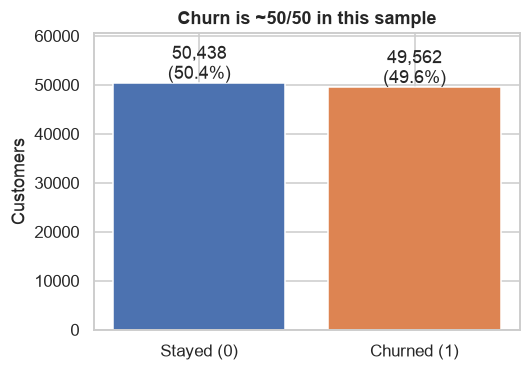

Overall churn rate: 49.56%


In [5]:
counts = df.churn.value_counts().sort_index()
rate = df.churn.mean()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Stayed (0)", "Churned (1)"], counts.values, color=[STAY, CHURN])
for i, v in enumerate(counts.values):
    ax.text(i, v + 800, f"{v:,}\n({v/len(df):.1%})", ha="center")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel("Customers")
ax.set_title("Churn is ~50/50 in this sample")
save(fig, "04_churn_balance"); plt.show()
print(f"Overall churn rate: {rate:.2%}")

**What we see:** 49.6% churned, 50.4% stayed, an almost perfect 50/50 split.

**Why this matters:**
- Real mobile operators lose roughly **1–3% of customers per month**. A 50% rate is not realistic. The sample was almost certainly **balanced on purpose**, with churners and stayers drawn in equal numbers (a common practice for public churn-modelling datasets).
- **For modelling:** balance is convenient. Accuracy is meaningful, and no resampling is needed. Still, we should report **ROC-AUC** and **lift / capture-rate** because those are what a retention team uses.
- **For the business case:** never say "Company A loses half its customers". When we put a dollar figure on the proposal, the predicted probabilities must be **rescaled to a realistic base churn rate**. A model's *ranking* of customers stays valid after rescaling, but its raw probabilities do not.

## 5. Data quality

Five checks, each tied to a decision we must make before modelling:

| Check | Decision it drives |
|---|---|
| 5.1 Missing values | drop, impute, or flag columns |
| 5.2 Is "missing" itself informative? | whether to keep a missing-indicator |
| 5.3 Impossible values | cleaning rules |
| 5.4 Undocumented columns | keep or drop |
| 5.5 Redundant columns | which duplicates to drop |

### 5.1 Where is data missing?

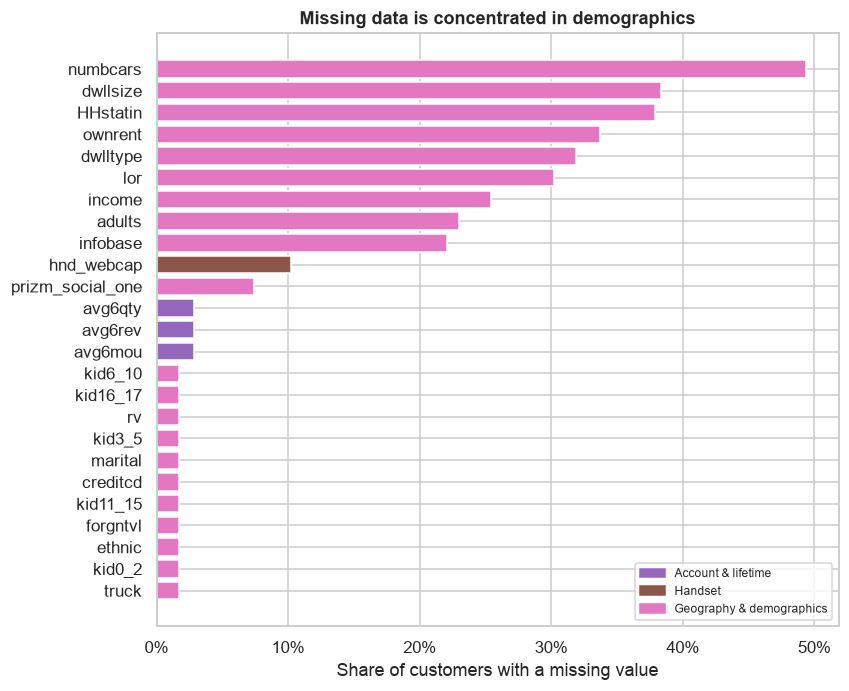

43 of 98 columns have at least one missing value
By family (mean missing share):
                          count   mean
Account & lifetime            3  0.028
Geography & demographics     22  0.145
Handset                       7  0.016
Money (monthly bill)          7  0.004
Usage (minutes & calls)       4  0.005


In [6]:
miss = df[features].isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fam_palette = dict(zip(FAMILIES, sns.color_palette("tab10", len(FAMILIES))))

top = miss.head(25)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index[::-1], top.values[::-1], color=[fam_palette[col2fam[c]] for c in top.index[::-1]])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Share of customers with a missing value")
ax.set_title("Missing data is concentrated in demographics")
handles = [plt.Rectangle((0, 0), 1, 1, color=fam_palette[f]) for f in FAMILIES if any(col2fam[c] == f for c in top.index)]
ax.legend(handles, [f for f in FAMILIES if any(col2fam[c] == f for c in top.index)], loc="lower right", fontsize=8)
save(fig, "05_missingness"); plt.show()

print(f"{len(miss)} of {len(features)} columns have at least one missing value")
print("By family (mean missing share):")
print(miss.groupby(miss.index.map(col2fam)).agg(["count", "mean"]).round(3))

**What we see:**
- The worst-affected columns are **demographics**: `numbcars` (49%), `dwllsize`/`HHstatin` (38%), `ownrent` (34%), `dwlltype` (32%), `lor` (30%), `income` (25%), `adults` (23%), `infobase` (22%). This pattern is typical of data bought from a third-party marketing database, where many customers simply cannot be matched.
- Handset: `hnd_webcap` is 10% missing, and `hnd_price` has a small number of gaps.
- Usage and billing columns are missing for only **~357 customers** (0.4%). These rows tend to be missing *all* their usage fields together.

**Meaning:** demographics are weak and incomplete, and they are also not something the company can change. We keep them as optional context, but the proposal should rely on usage, account and handset behaviour.

### 5.2 Is "missing" itself a signal?

**Why:** sometimes the *fact* that a value is missing tells you something. A customer with no usage record may already be inactive, and a missing handset field may indicate an old phone. If so, we should keep that information instead of filling the gap with an average.

In [7]:
rows = []
for c in miss.index[df[miss.index].isna().sum() >= 100]:   # ignore columns missing in only a handful of rows
    m = df[c].isna()
    rows.append({"column": c, "family": col2fam[c], "pct_missing": m.mean(),
                 "churn_if_missing": df.loc[m, "churn"].mean(), "churn_if_present": df.loc[~m, "churn"].mean()})
miss_sig = pd.DataFrame(rows).set_index("column")
miss_sig["gap_pts"] = (miss_sig.churn_if_missing - miss_sig.churn_if_present) * 100
miss_sig.sort_values("gap_pts", key=abs, ascending=False).head(16).round(3)

,family,pct_missing,churn_if_missing,churn_if_present,gap_pts
column,,,,,
change_mou,Usage (minutes & calls),0.009,0.761,0.493,26.771
change_rev,Money (monthly bill),0.009,0.761,0.493,26.771
totmrc_Mean,Money (monthly bill),0.004,0.686,0.495,19.134
da_Mean,Money (monthly bill),0.004,0.686,0.495,19.134
ovrmou_Mean,Usage (minutes & calls),0.004,0.686,0.495,19.134
vceovr_Mean,Money (monthly bill),0.004,0.686,0.495,19.134
ovrrev_Mean,Money (monthly bill),0.004,0.686,0.495,19.134
datovr_Mean,Money (monthly bill),0.004,0.686,0.495,19.134
roam_Mean,Usage (minutes & calls),0.004,0.686,0.495,19.134


In [8]:
usage_missing = df.rev_Mean.isna()
zero_usage = df.mou_Mean.eq(0)
print(f"Usage block missing : {usage_missing.sum():>5} customers, churn rate {df.loc[usage_missing, 'churn'].mean():.1%}")
print(f"Zero minutes of use : {zero_usage.sum():>5} customers, churn rate {df.loc[zero_usage, 'churn'].mean():.1%}")
print(f"Everyone            : {len(df):>5} customers, churn rate {rate:.1%}")

Usage block missing :   357 customers, churn rate 68.6%
Zero minutes of use :  1615 customers, churn rate 79.8%
Everyone            : 100000 customers, churn rate 49.6%


**What we see:**
- Customers with **no usage record churn at ~69%**, those with no usage *trend* (`change_mou` missing, ~0.9%) at ~76%, and those with **zero minutes of use at ~80%**. These are "silent" customers who have effectively stopped using the service already.
- When `hnd_webcap` is missing, churn is ~59% vs ~49% otherwise. Missing handset information likely points to older or unrecorded phones.
- The opposite case: when `hnd_price` is missing (0.8%), churn is only ~37%. Missingness can point either way, which is exactly why we keep it as information rather than averaging it away.
- When demographics are missing, churn is a few points higher (about 51% vs 49%). This is a real but small effect.

**Decisions:**
1. Do **not** fill these values with the column average blindly. Add a missing-indicator, or use a tree model that handles `NaN` natively (XGBoost/LightGBM do).
2. Keep **"zero usage" as a named flag**. It is an easy, explainable early-warning rule ("a customer who stops calling is about to leave").

### 5.3 Impossible or suspicious values

**Why:** negative ages or negative bills cannot be real. They are recording errors or billing adjustments (refunds), and they can distort averages and charts.

In [9]:
checks = {
    "eqpdays < 0 (negative phone age)": df.eqpdays < 0,
    "rev_Mean < 0 (negative bill)": df.rev_Mean < 0,
    "totmrc_Mean < 0 (negative plan fee)": df.totmrc_Mean < 0,
    "eqpdays > months*31 (phone older than account)": df.eqpdays > df.months * 31 + 31,
    "actvsubs > uniqsubs (more active than total lines)": df.actvsubs > df.uniqsubs,
}
pd.DataFrame({"n_rows": {k: int(v.sum()) for k, v in checks.items()}})

,n_rows
eqpdays < 0 (negative phone age),133
rev_Mean < 0 (negative bill),5
totmrc_Mean < 0 (negative plan fee),23
eqpdays > months*31 (phone older than account),0
actvsubs > uniqsubs (more active than total lines),0


In [10]:
key_num = ["rev_Mean", "totmrc_Mean", "mou_Mean", "ovrrev_Mean", "drop_vce_Mean", "custcare_Mean",
           "months", "eqpdays", "hnd_price", "uniqsubs"]
desc = df[key_num].describe(percentiles=[.5, .99]).T[["min", "50%", "mean", "99%", "max"]]
desc["max / 99th pct"] = desc["max"] / desc["99%"]
desc.round(1)

,min,50%,mean,99%,max,max / 99th pct
rev_Mean,-6.2,48.2,58.7,227.9,3843.3,16.9
totmrc_Mean,-26.9,45.0,46.2,118.0,410.0,3.5
mou_Mean,0.0,355.5,513.6,2422.4,12206.8,5.0
ovrrev_Mean,0.0,1.0,13.6,139.3,1102.4,7.9
drop_vce_Mean,0.0,3.0,6.0,41.3,232.7,5.6
custcare_Mean,0.0,0.0,1.8,20.3,675.3,33.2
months,6.0,16.0,18.8,49.0,61.0,1.2
eqpdays,-5.0,342.0,391.9,1165.0,1823.0,1.6
hnd_price,10.0,100.0,101.9,200.0,500.0,2.5
uniqsubs,1.0,1.0,1.5,5.0,196.0,39.2


**What we see:**
- A handful of negative values: **133 negative phone ages** and a few negative bills/plan fees. These are tiny in number, so set them to missing (or clip to 0).
- Consistency checks pass: no phone is older than its account, and active lines never exceed total lines. The tables agree with each other.
- **Heavy right tails:** the maximum is often 5–30× the 99th percentile. For example, the median bill is about \$48, while the largest is \$3,843 and the largest `uniqsubs` is 196 lines (probably a business account). The **mean is well above the median** for money and usage.

**Decisions:** tree models are robust to extreme values, so no clipping is needed for them. For **charts**, use log scales or percentile bins, otherwise a few outliers flatten everything. For **business numbers**, quote the **median**, not the mean, as the "typical" customer.

### 5.4 Undocumented columns

Two columns have no description in the dataset overview: `recv_sms_Mean` and `iwylis_vce_Mean`. By analogy with their neighbours, they are probably "received SMS" and "inbound wireless-to-wireless voice calls". Let's see whether they carry any information.

In [11]:
for c in ["recv_sms_Mean", "iwylis_vce_Mean"]:
    s = df[c]
    print(f"{c:<16} non-zero: {(s > 0).mean():6.1%} | median {s.median():.2f} | corr with mouiwylisv_Mean {s.corr(df.mouiwylisv_Mean):.2f}")

recv_sms_Mean    non-zero:   0.9% | median 0.00 | corr with mouiwylisv_Mean 0.02
iwylis_vce_Mean  non-zero:  69.5% | median 2.00 | corr with mouiwylisv_Mean 0.79


**What we see:** `recv_sms_Mean` is almost always zero (SMS was barely used in this era), so it carries close to no information and can be dropped. `iwylis_vce_Mean` tracks its documented "minutes" sibling `mouiwylisv_Mean` closely, which supports reading it as *inbound wireless-to-wireless call count*.

**Decision:** drop `recv_sms_Mean`. Keep `iwylis_vce_Mean`, stating the assumption on the slide; the brief explicitly rewards handling ambiguity sensibly.

### 5.5 Redundant (near-duplicate) columns

**Why:** if two columns carry almost the same information, keeping both adds nothing and makes feature-importance charts misleading, because the credit gets split between twins. We look for pairs with correlation above 0.95.

In [12]:
corr = df[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
dupes = upper.stack().loc[lambda s: s > 0.95].sort_values(ascending=False).rename("abs_corr").to_frame()
print(f"{len(dupes)} near-duplicate pairs (|r| > 0.95)")
dupes.round(3)

19 near-duplicate pairs (|r| > 0.95)


,,abs_corr
totcalls,adjqty,1.000
totmou,adjmou,1.000
totrev,adjrev,0.998
plcd_vce_Mean,attempt_Mean,0.998
comp_vce_Mean,complete_Mean,0.998
ovrrev_Mean,vceovr_Mean,0.995
ccrndmou_Mean,cc_mou_Mean,0.989
attempt_Mean,complete_Mean,0.986
plcd_vce_Mean,comp_vce_Mean,0.985
comp_vce_Mean,attempt_Mean,0.984


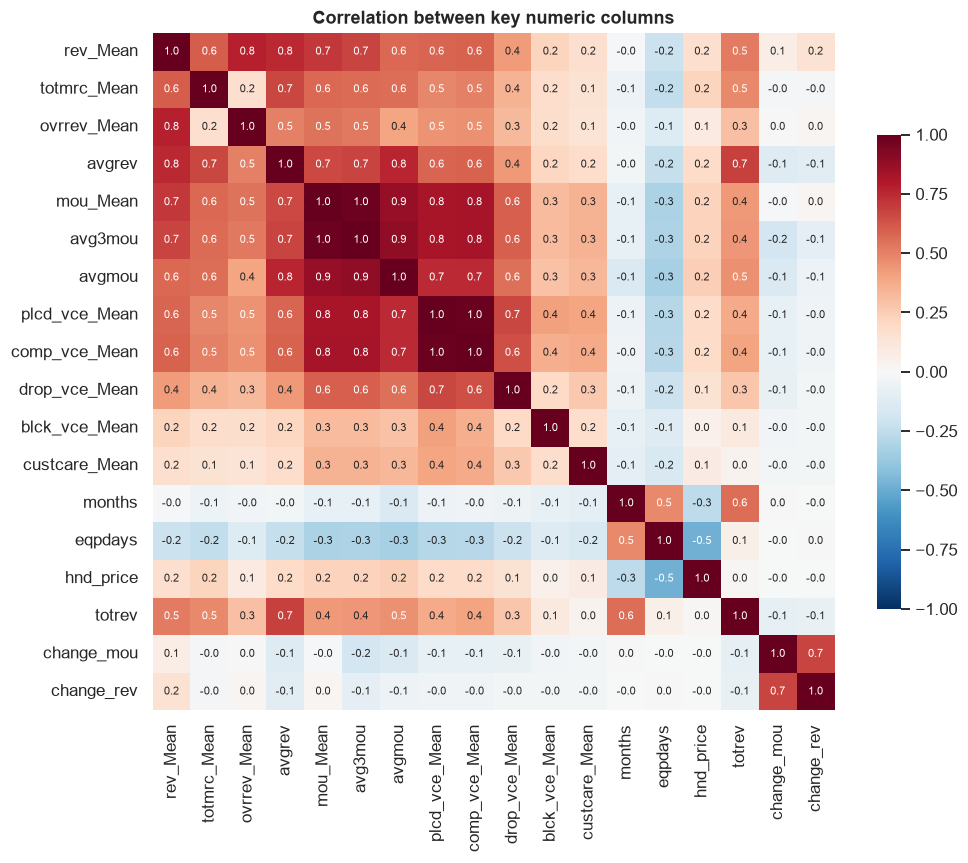

In [13]:
heat_cols = ["rev_Mean", "totmrc_Mean", "ovrrev_Mean", "avgrev", "mou_Mean", "avg3mou", "avgmou", "plcd_vce_Mean",
             "comp_vce_Mean", "drop_vce_Mean", "blck_vce_Mean", "custcare_Mean", "months", "eqpdays", "hnd_price",
             "totrev", "change_mou", "change_rev"]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[heat_cols].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation between key numeric columns")
save(fig, "05_correlation"); plt.show()

**What we see:** 19 near-duplicate pairs, falling into a few clear groups:
- **Adjusted vs raw lifetime totals:** `adjrev`≈`totrev`, `adjmou`≈`totmou`, `adjqty`≈`totcalls` (r ≈ 0.999).
- **Attempted vs completed calls:** `attempt_Mean` ≈ `plcd_vce_Mean` ≈ `complete_Mean` ≈ `comp_vce_Mean`.
- **Overage:** `ovrrev_Mean` ≈ `vceovr_Mean` ≈ `ovrmou_Mean` (almost all overage is voice).
- **Recent vs current usage:** `mou_Mean` ≈ `avg3mou` ≈ `avg6mou`.
- **Customer care:** `ccrndmou_Mean` ≈ `cc_mou_Mean` (rounded vs unrounded minutes).

In the heatmap, money and usage form a bright block. Heavy users pay more, which is unsurprising. `eqpdays`, `months` and `change_*` sit apart, so they carry *independent* information.

**Decision:** keep one representative per group for interpretable models (logistic regression). For tree models, duplicates do little harm to accuracy, but importance should be read **by family** rather than by single column.

## 6. Customer profile — what does a typical customer look like?

**Why:** before comparing churners with stayers, we need a feel for the "normal" ranges. This also gives the slides a one-line customer portrait.

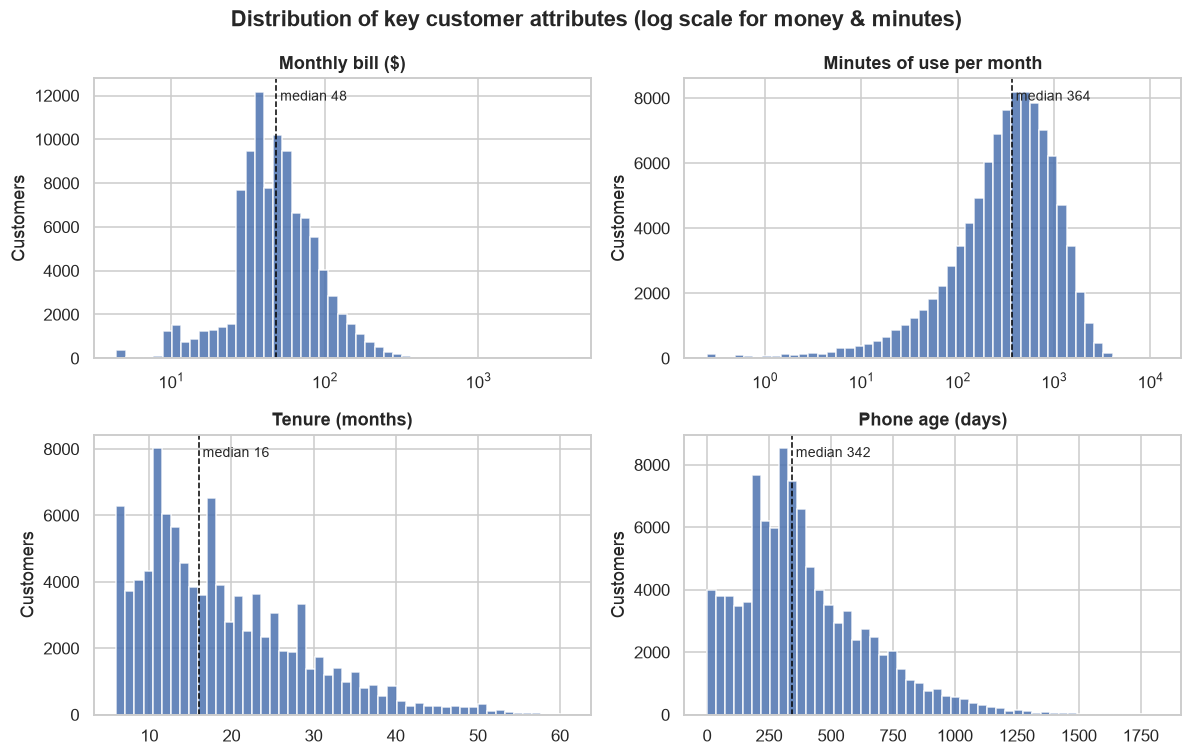

Share paying any overage   : 57%
Share using any data calls : 15%
Share with any roaming     : 31%
Share with refurbished phone: 14%
Share on a single line     : 62%


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
specs = [("rev_Mean", "Monthly bill ($)", True), ("mou_Mean", "Minutes of use per month", True),
         ("months", "Tenure (months)", False), ("eqpdays", "Phone age (days)", False)]
for ax, (c, label, logx) in zip(axes.flat, specs):
    s = df[c].dropna()
    if logx:
        s = s[s > 0]
        bins = np.logspace(np.log10(s.quantile(.001)), np.log10(s.max()), 50)
        ax.set_xscale("log")
    else:
        s = s.clip(lower=0)
        bins = 50
    ax.hist(s, bins=bins, color=STAY, alpha=.85)
    ax.axvline(s.median(), color="black", ls="--", lw=1)
    ax.text(s.median(), ax.get_ylim()[1] * .92, f" median {s.median():,.0f}", fontsize=9)
    ax.set_title(label); ax.set_ylabel("Customers")
fig.suptitle("Distribution of key customer attributes (log scale for money & minutes)", fontweight="bold")
fig.tight_layout(); save(fig, "06_profile"); plt.show()

share = lambda m: f"{m.mean():.0%}"
print("Share paying any overage   :", share(df.ovrmou_Mean > 0))
print("Share using any data calls :", share(df.plcd_dat_Mean > 0))
print("Share with any roaming     :", share(df.roam_Mean > 0))
print("Share with refurbished phone:", share(df.refurb_new == "R"))
print("Share on a single line     :", share(df.uniqsubs == 1))

**What we see:**
- **Bill:** median ~\$48/month, mostly the plan fee (median `totmrc_Mean` ~\$45). 57% pay at least some overage.
- **Minutes:** median ~355 min/month (about 12 minutes per day), with a long tail of very heavy users.
- **Tenure:** 6 to 61 months, median 16. **No one has fewer than 6 months**, so very new customers were excluded from the sample. There is a visible pile-up of customers around 11–12 months.
- **Phone age:** median ~340 days, with some phones up to 5 years old.
- Only **15% use any data**. This is a voice-era dataset, so the market analysis should not pitch smartphone or 5G-era services.

**Typical customer (for the slides):** *about 16 months with Company A, pays ~\$48/month, talks ~12 minutes a day, carries a ~\$100 phone that is about a year old.*

## 7. Churn drivers — what goes together with leaving?

**Approach:** for each candidate column, split customers into groups (bins, or categories) and plot the **churn rate per group**, compared with the overall rate (grey dashed line). Each bar also shows the number of customers and a 95% error bar, so we do not over-read small groups.

Why churn **rate per group**, and not overlapping histograms as in the tutorial? A rate answers the business question directly: "if a customer is in this group, how likely are they to leave?" Histograms of 100k points also hide differences in the tails.

We go family by family, and for each driver ask **"can the company act on it?"**, because only actionable drivers become proposal levers.

In [15]:
def churn_by(group, ax=None, title="", xlabel="", min_n=200, rotate=0, sort=False, horizontal=False):
    # Plot churn rate per group with 95% CI and customer counts.
    g = df.groupby(group, observed=True)["churn"].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    if sort:
        g = g.sort_values("mean")
    err = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    labels = [str(i) for i in g.index]
    colors = [CHURN if m > rate else STAY for m in g["mean"]]
    ax = ax or plt.subplots(figsize=(8, 4))[1]
    if horizontal:
        ax.barh(labels, g["mean"], xerr=err, color=colors, alpha=.9)
        ax.axvline(rate, color=BASE, ls="--", lw=1)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
        ax.set_xlabel("Churn rate"); ax.set_ylabel(xlabel)
        for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
            ax.text(m + .02, i, f"{m:.0%} (n={n:,})", va="center", fontsize=8)
        ax.set_xlim(0, max(.8, g["mean"].max() + .2))
    else:
        ax.bar(labels, g["mean"], yerr=err, color=colors, alpha=.9)
        ax.axhline(rate, color=BASE, ls="--", lw=1)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
        ax.set_ylabel("Churn rate"); ax.set_xlabel(xlabel)
        for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
            ax.text(i, m + err.iloc[i] + .01, f"{m:.0%}\nn={n:,}", ha="center", fontsize=7)
        ax.set_ylim(0, max(.8, g["mean"].max() + .15))
        ax.tick_params(axis="x", rotation=rotate)
    ax.set_title(title)
    return g

def bins(col, edges, labels):
    return pd.cut(df[col], edges, labels=labels)

### 7.1 Tenure: the contract cliff

**Why:** mobile customers in this market typically sign **12-month (or longer) contracts**, and leaving early costs a fee. If contracts drive behaviour, churn should spike when the contract ends.

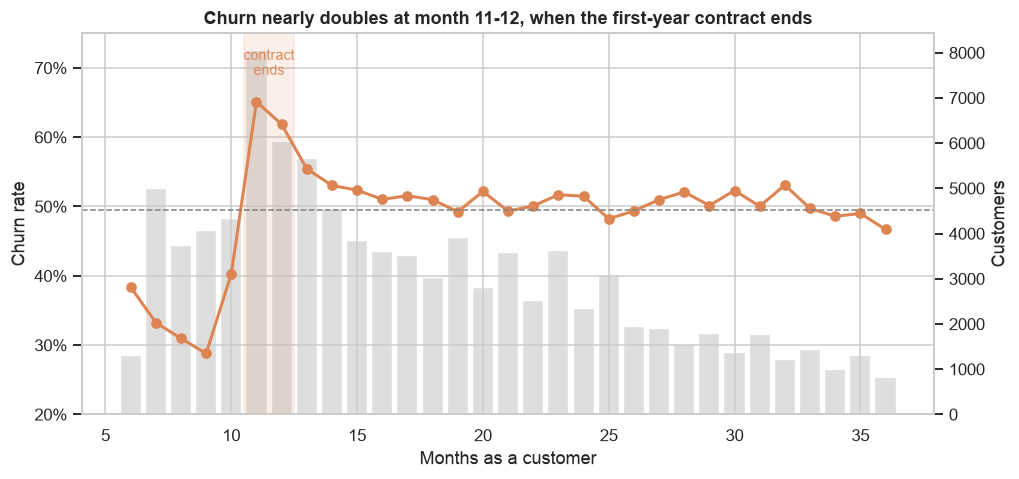

months,6,7,8,9,10,11,12,13,14,15
mean,0.384,0.333,0.31,0.288,0.403,0.651,0.619,0.554,0.53,0.524
size,1295.000,4979.000,3728.00,4066.000,4313.000,8029.000,6033.000,5651.000,4552.00,3835.000


In [16]:
t = df[df.months <= 36].groupby("months")["churn"].agg(["mean", "size"])

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax2 = ax1.twinx()
ax2.bar(t.index, t["size"], color=BASE, alpha=.25, label="Customers (right axis)")
ax1.plot(t.index, t["mean"], marker="o", color=CHURN, lw=2, label="Churn rate")
ax1.axhline(rate, color=BASE, ls="--", lw=1)
ax1.axvspan(10.5, 12.5, color=CHURN, alpha=.12)
ax1.text(11.5, .69, "contract\nends", ha="center", fontsize=9, color=CHURN)
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax1.set_ylim(.2, .75)
ax1.set_xlabel("Months as a customer"); ax1.set_ylabel("Churn rate"); ax2.set_ylabel("Customers")
ax2.grid(False)
ax1.set_title("Churn nearly doubles at month 11-12, when the first-year contract ends")
save(fig, "07_tenure_cliff"); plt.show()

t.loc[6:15].T.round(3)

**What we see:** this is the most striking pattern in the data.
- Months 7–10: churn is **29–40%**, well *below* average. These customers are locked into their contract.
- **Month 11: 65%, month 12: 62%.** Churn nearly doubles exactly at the 1-year mark, and these two months hold about 14,000 customers.
- After month 13, churn settles back toward ~50%.

**Meaning:**
- A **contract-expiry effect**: customers wait out the contract, then shop around.
- **Actionable: yes.** The company knows every customer's contract-end date. A renewal offer at **month 9–10**, *before* the window opens, is a clear and cheap lever.
- **Modelling:** tenure should enter as "months until / since contract end" or as a 10–12 month flag, not only as a raw number.

### 7.2 Phone age: older phones, more churn

**Why:** in this era, carriers subsidised phones in exchange for contracts. A customer with an ageing phone has a strong reason to switch: *a new carrier offers a free new phone*.

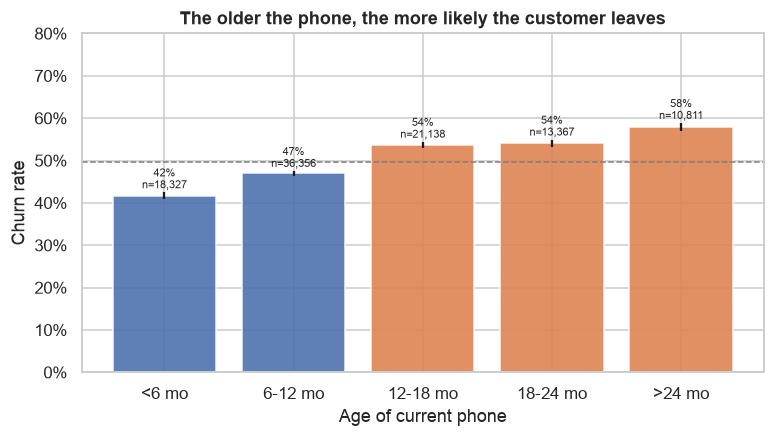

In [17]:
eq_bins = bins("eqpdays", [-np.inf, 180, 365, 540, 730, np.inf], ["<6 mo", "6-12 mo", "12-18 mo", "18-24 mo", ">24 mo"])
fig, ax = plt.subplots(figsize=(8, 4))
churn_by(eq_bins, ax, "The older the phone, the more likely the customer leaves", "Age of current phone")
save(fig, "07_phone_age"); plt.show()

**What we see:** a steady rise from **42% (phone < 6 months old) to 58% (> 2 years)**, a 16-point gap. Phone age is also the single strongest numeric signal in the data (Section 8).

**Is it just tenure in disguise?** Older phones belong to older accounts, and account age has its own pattern (7.1). The next chart separates the two effects.

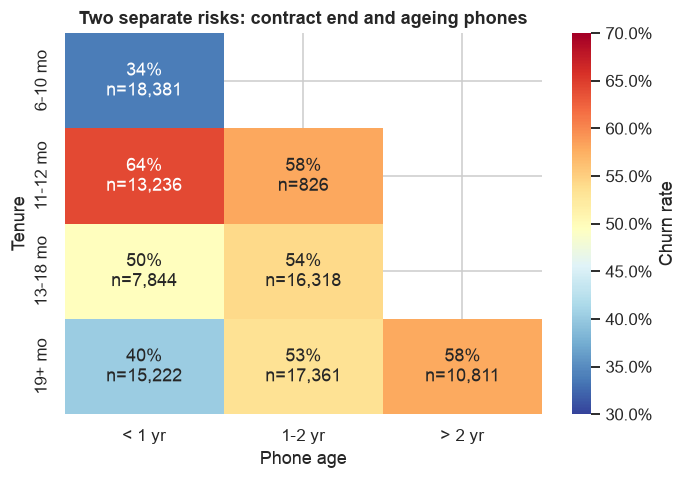

In [18]:
ten_b = bins("months", [0, 10, 12, 18, np.inf], ["6-10 mo", "11-12 mo", "13-18 mo", "19+ mo"])
eq_b = bins("eqpdays", [-np.inf, 365, 730, np.inf], ["< 1 yr", "1-2 yr", "> 2 yr"])
pv = df.pivot_table(index=ten_b, columns=eq_b, values="churn", aggfunc="mean", observed=False)
pn = df.pivot_table(index=ten_b, columns=eq_b, values="churn", aggfunc="size", observed=False)
pv = pv.where(pn >= 300)   # hide cells with too few customers to trust

annot = pv.map(lambda v: "" if pd.isna(v) else f"{v:.0%}") + pn.map(lambda n: f"\nn={n:,}" if n >= 300 else "")
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(pv, annot=annot, fmt="", cmap="RdYlBu_r", center=rate, vmin=.3, vmax=.7, ax=ax,
            cbar_kws={"format": mtick.PercentFormatter(1), "label": "Churn rate"})
ax.set_xlabel("Phone age"); ax.set_ylabel("Tenure")
ax.set_title("Two separate risks: contract end and ageing phones")
save(fig, "07_tenure_x_phone"); plt.show()

**What we see:**
- Among long-tenure customers (19+ months), churn climbs from **40% (phone < 1 yr) → 53% (1–2 yr) → 58% (> 2 yr)**. Same tenure, different phone age, very different risk. **Phone age matters on its own.**
- The 11–12-month row is hot (~60%+) regardless of phone age. **Contract end matters on its own.**
- Interpretation: the low churn of long-tenure customers with new phones suggests that **a recent phone upgrade (which usually comes with a new contract) "resets" loyalty.**

**Meaning:** two distinct, **actionable** levers. (1) Contract-renewal timing. (2) Handset-upgrade offers for customers whose phone is over ~1 year old. Both are standard tools in the telecom industry, so they will be credible to executives.

### 7.3 Handset characteristics

**Why:** beyond age, the *quality* of the phone may matter. Cheap or limited phones give a weaker experience and less reason to stay.

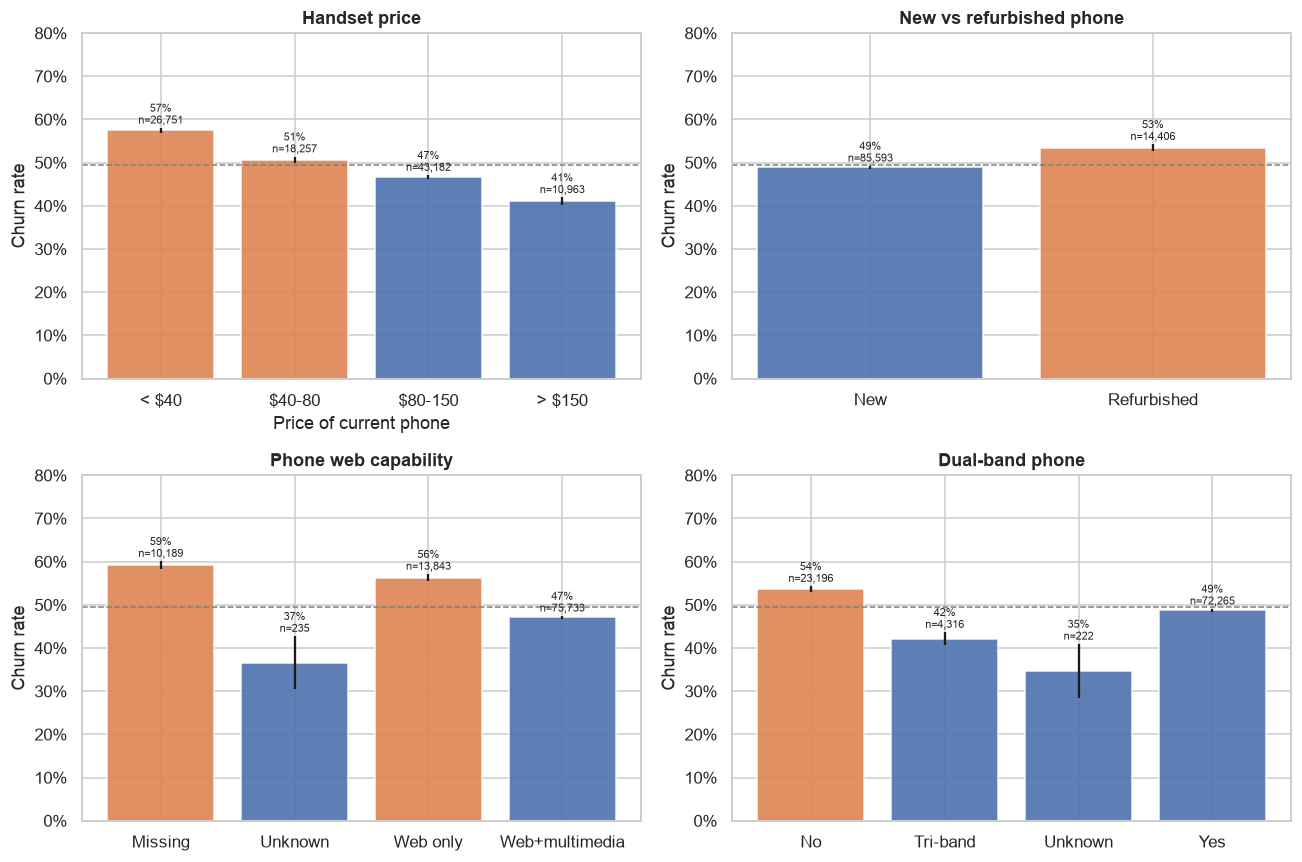

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
churn_by(bins("hnd_price", [0, 40, 80, 150, np.inf], ["< $40", "$40-80", "$80-150", "> $150"]),
         axes[0, 0], "Handset price", "Price of current phone")
churn_by(df.refurb_new.map({"N": "New", "R": "Refurbished"}), axes[0, 1], "New vs refurbished phone")
churn_by(df.hnd_webcap.fillna("Missing").map({"WCMB": "Web+multimedia", "WC": "Web only",
                                              "UNKW": "Unknown", "Missing": "Missing"}),
         axes[1, 0], "Phone web capability")
churn_by(df.dualband.map({"Y": "Yes", "N": "No", "T": "Tri-band", "U": "Unknown"}), axes[1, 1], "Dual-band phone")
fig.tight_layout(); save(fig, "07_handset"); plt.show()

**What we see:**
- **Price:** customers with phones under \$40 churn at **~57%**, compared with **~41%** for phones over \$150.
- **Refurbished** phones: 53% vs 49% for new phones.
- **Basic web-only** phones (56%) and **unknown capability** (59%) churn more than full web+multimedia phones (47%).
- **Single-band** phones (no dual-band): 54% vs 49%.

**Meaning:** every handset signal points the same way. **Customers on cheap, old, or basic phones are at higher risk.** This supports a *targeted* handset-upgrade offer. Upgrading everyone would be expensive, but upgrading the high-risk group is affordable. Price and phone type are partly proxies for a customer's value and engagement, so the model must weigh them together.

### 7.4 Usage level and usage trend

**Why:** a customer who is about to leave often uses the service less beforehand. Some have already started using a competitor. Two different questions follow: *how much* do they use, and *is it falling*?

`change_mou` = current month's minutes minus the previous 3-month average. Negative means usage is dropping.

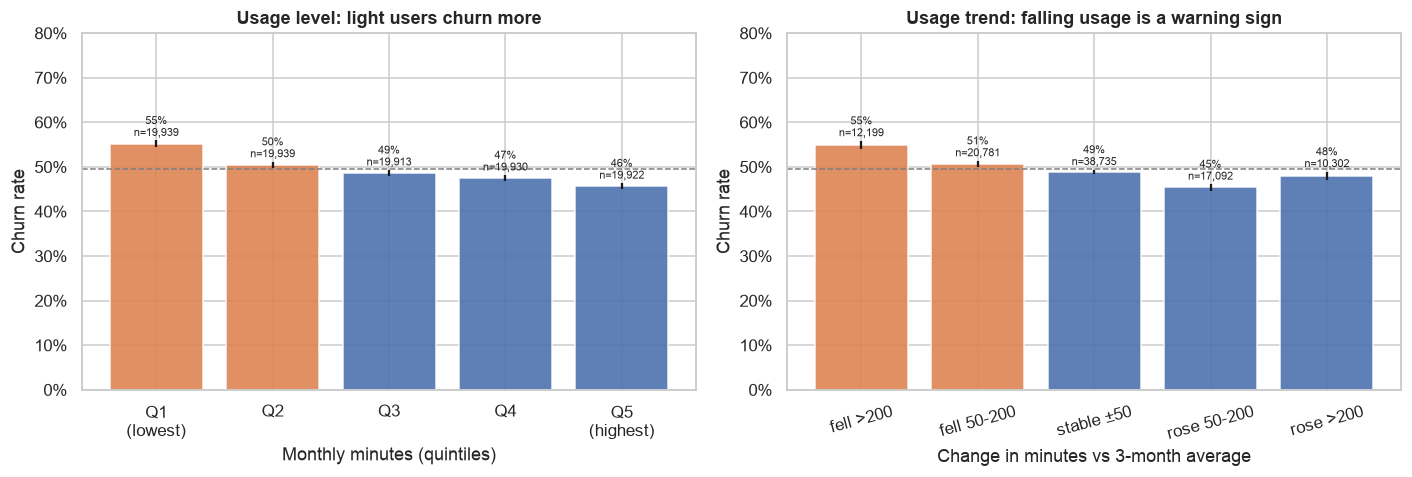

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mou_dec = pd.qcut(df.mou_Mean, 5, labels=["Q1\n(lowest)", "Q2", "Q3", "Q4", "Q5\n(highest)"])
churn_by(mou_dec, axes[0], "Usage level: light users churn more", "Monthly minutes (quintiles)")
chg = bins("change_mou", [-np.inf, -200, -50, 50, 200, np.inf],
           ["fell >200", "fell 50-200", "stable ±50", "rose 50-200", "rose >200"])
churn_by(chg, axes[1], "Usage trend: falling usage is a warning sign", "Change in minutes vs 3-month average", rotate=15)
fig.tight_layout(); save(fig, "07_usage"); plt.show()

**What we see:**
- **Level:** the lightest 20% of users churn most, and the heaviest users churn least. Light users get less value from the service, so leaving costs them little.
- **Trend:** customers whose minutes **fell by more than 200** churn at **~55%**, vs ~46% for those whose usage grew. Together with the ~80% churn of zero-usage customers (5.2), this shows that **customers fade out before they leave.**

**Meaning:** a usage drop is an **early-warning trigger** that can be monitored monthly. It is *partly* actionable. You cannot force usage, but a drop can trigger an outreach (a check-in call, a plan review, or a better-fitting plan). It is also a strong model feature.

### 7.5 Revenue: does the size of the bill matter?

**Why:** if high-paying customers churned *more*, the problem would be urgent and value-weighted. If churn is flat across bill sizes, risk and value are independent, and we should target by *both*.

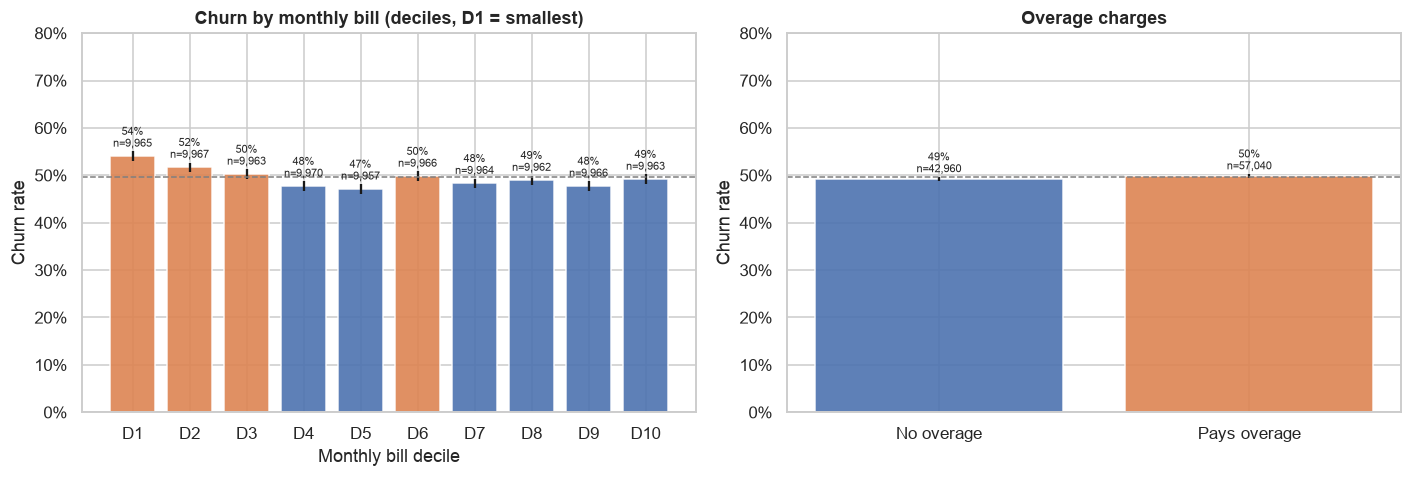

rev_Mean         D1    D2    D3    D4    D5    D6    D7    D8    D9    D10
median bill $  15.0  30.0  33.0  37.0  44.0  51.0  58.0  71.0  89.0  136.0


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rev_dec = pd.qcut(df.rev_Mean, 10, labels=[f"D{i}" for i in range(1, 11)])
churn_by(rev_dec, axes[0], "Churn by monthly bill (deciles, D1 = smallest)", "Monthly bill decile")
churn_by(np.where(df.ovrmou_Mean > 0, "Pays overage", "No overage"), axes[1], "Overage charges")
fig.tight_layout(); save(fig, "07_revenue"); plt.show()
print(df.groupby(rev_dec, observed=True).rev_Mean.median().round(0).to_frame("median bill $").T)

**What we see:**
- Churn is **fairly flat across bill sizes**. Only the smallest-bill decile is clearly higher (~54%); the rest sit at 47–50%.
- Paying overage makes almost no difference (49% vs 50%). "Bill shock" is *not* a major driver in this data.

**Meaning:** high-value customers are about as likely to leave as low-value ones, so **losing a high-value customer costs far more for the same probability.** The proposal should rank customers by **expected revenue loss = churn probability × monthly revenue**, not by probability alone. This is a simple, executive-friendly idea that sets the proposal apart from a plain "churn model".

### 7.6 Service quality and customer-care contact

**Why:** poor network quality (dropped calls) is a classic churn reason in telecom. Calls to customer care are often assumed to signal complaints. We test both.

We use the **dropped-call rate** (dropped ÷ attempted), not the raw count. Heavy users naturally have more dropped calls simply because they make more calls, and the rate removes that bias.

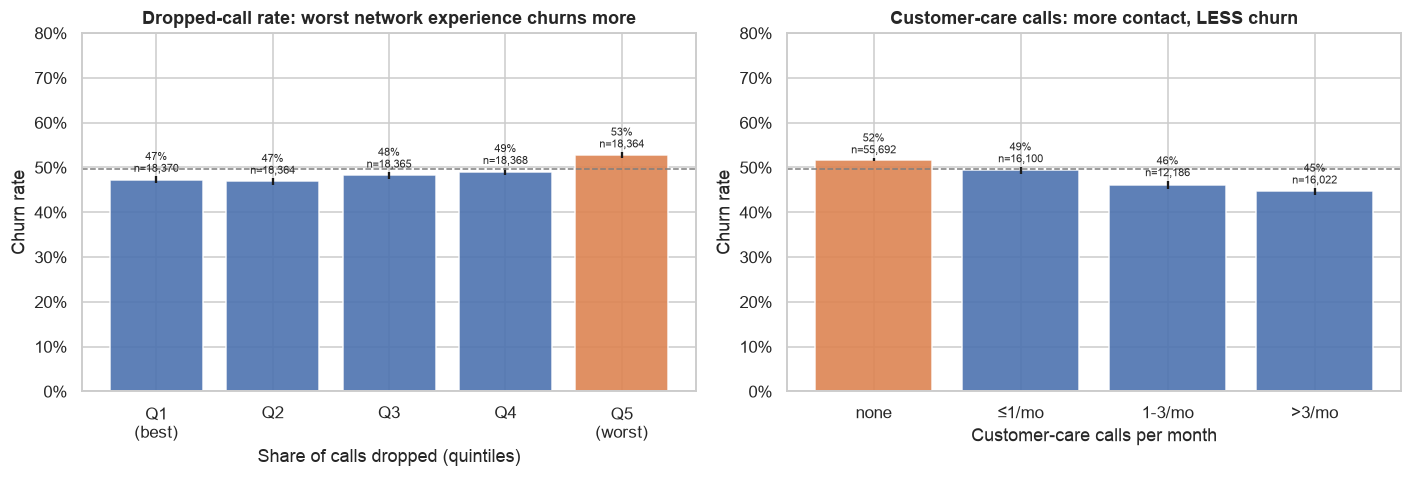

Median dropped-call rate: 3.3%


In [22]:
drop_rate = df.drop_vce_Mean / df.plcd_vce_Mean.replace(0, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
churn_by(pd.qcut(drop_rate, 5, labels=["Q1\n(best)", "Q2", "Q3", "Q4", "Q5\n(worst)"]), axes[0],
         "Dropped-call rate: worst network experience churns more", "Share of calls dropped (quintiles)")
churn_by(bins("custcare_Mean", [-1, 0, 1, 3, np.inf], ["none", "≤1/mo", "1-3/mo", ">3/mo"]), axes[1],
         "Customer-care calls: more contact, LESS churn", "Customer-care calls per month")
fig.tight_layout(); save(fig, "07_quality_care"); plt.show()
print("Median dropped-call rate:", f"{drop_rate.median():.1%}")

**What we see:**
- **Dropped calls:** the worst 20% (most calls dropped) churn at **~53%**, vs ~47% for the best. The effect is real but moderate.
- **Customer care (counter-intuitive):** customers who **never** call care churn the *most* (**52%**). Those calling more than 3 times a month churn the *least* (**45%**).

**Meaning:**
- Network quality is a real driver. It is actionable for the company, but slow and expensive (infrastructure investment). For a PoC, it is better used as a **targeting signal**: offer goodwill credits to customers who suffer many dropped calls.
- **Care calls are a sign of engagement, not anger.** Customers who interact with the company stay longer, while silent customers leave without warning. This supports a **proactive outreach** proposal: *contact customers before they go quiet*.
- Care: this pattern is correlational. It does *not* prove that calling customers reduces churn. A pilot with a control group (Section 10) would test that.

### 7.7 Account characteristics: credit class, spending limit, household lines

`crclscod` has 54 codes. We group by **first letter** (A, B, C…). In the original coding, earlier letters are generally understood as better credit, but Company A did not confirm this. We state it as an assumption.

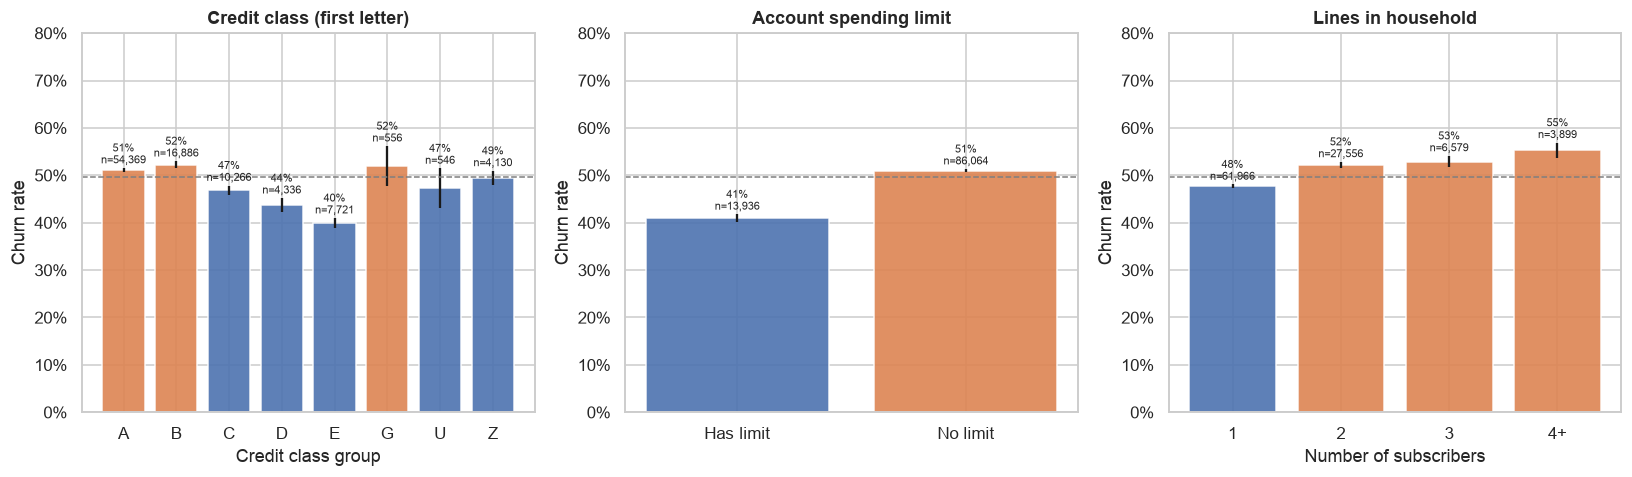

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
churn_by(df.crclscod.str[0], axes[0], "Credit class (first letter)", "Credit class group", min_n=500)
churn_by(df.asl_flag.map({"Y": "Has limit", "N": "No limit"}), axes[1], "Account spending limit")
churn_by(bins("uniqsubs", [0, 1, 2, 3, np.inf], ["1", "2", "3", "4+"]), axes[2],
         "Lines in household", "Number of subscribers")
fig.tight_layout(); save(fig, "07_account"); plt.show()

**What we see:**
- **Credit:** the most common classes (A, B) churn at ~51–52%, while classes C, D, E churn *less* (40–47%). A plausible explanation, *if* later letters mean weaker credit, is that **customers with weaker credit have fewer alternatives**, because competitors run credit checks too.
- **Spending limit:** accounts with a limit churn at 41% vs 51%. This is consistent with the credit story.
- **Household lines:** more lines means *more* churn (48% for 1 line → 55% for 4+). This is surprising, since family plans usually "lock in" households. A possible reason is that multi-line households are attractive targets for competitor family deals.

**Meaning:** these describe *who* is at risk rather than something to change, so they are good **targeting features** for the model. Multi-line households deserve a specific mention: losing one means losing several lines at once.

### 7.8 Geography and demographics

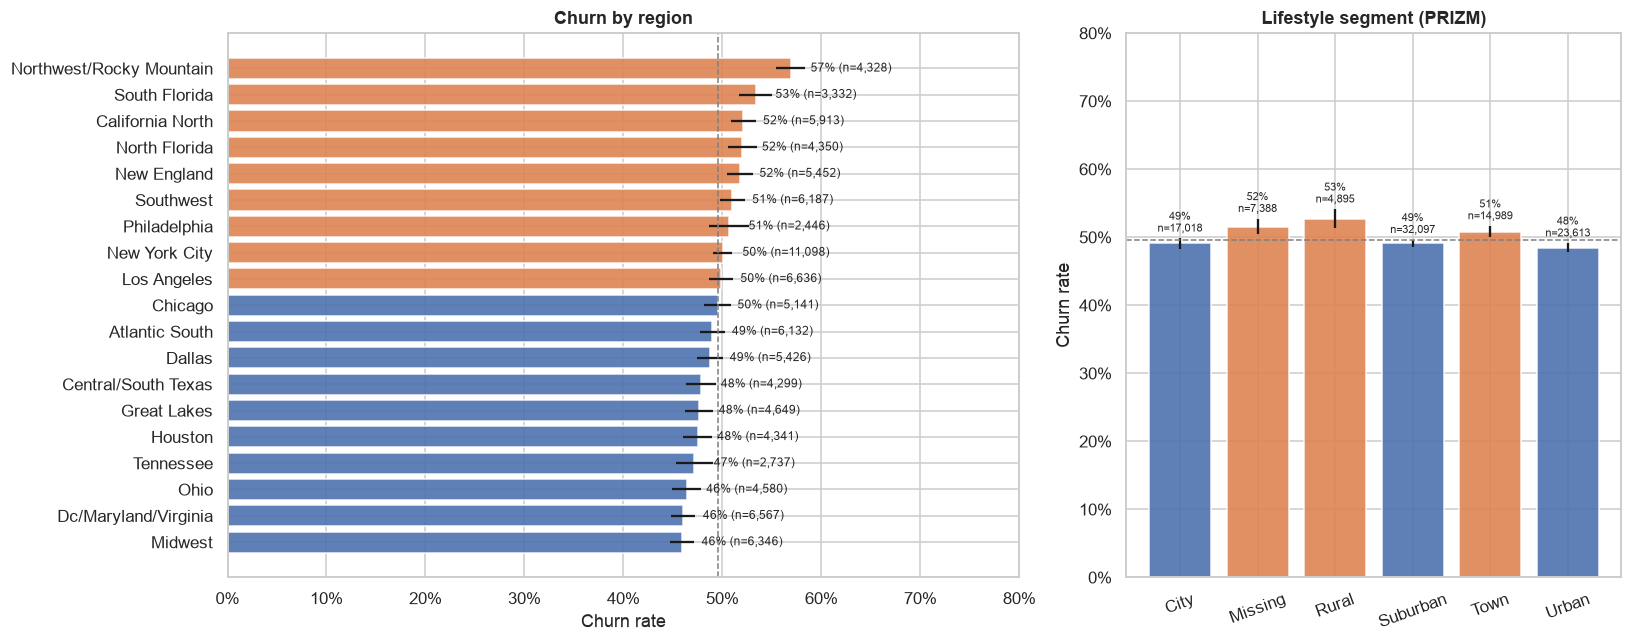

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.6, 1]})
area_short = df.area.str.replace(" AREA", "").str.title()
churn_by(area_short, axes[0], "Churn by region", "", sort=True, horizontal=True)
churn_by(df.prizm_social_one.fillna("Missing").map(
    {"S": "Suburban", "U": "Urban", "C": "City", "T": "Town", "R": "Rural", "Missing": "Missing"}),
    axes[1], "Lifestyle segment (PRIZM)", rotate=20)
fig.tight_layout(); save(fig, "07_geo_demo"); plt.show()

In [25]:
# Quick scan of all remaining demographic columns: how far does any group deviate from the average?
demo = ["income", "adults", "marital", "ownrent", "lor", "dwlltype", "creditcd", "truck", "rv", "forgntvl",
        "numbcars", "kid0_2", "kid3_5", "kid6_10", "kid11_15", "kid16_17", "ethnic", "HHstatin", "dwllsize"]
spread = {}
for c in demo:
    g = df.groupby(df[c].astype(str), observed=True).churn.agg(["mean", "size"])
    g = g[g["size"] >= 1000]
    spread[c] = (g["mean"].max() - g["mean"].min()) * 100
pd.Series(spread, name="max gap between groups (pts)").sort_values(ascending=False).round(1).to_frame().T

,ethnic,lor,dwllsize,marital,income,ownrent,numbcars,kid0_2,HHstatin,creditcd,adults,dwlltype,kid3_5,forgntvl,kid16_17,kid11_15,truck,kid6_10,rv
max gap between groups (pts),18.4,8.3,3.9,3.8,3.4,3.2,2.8,2.5,2.3,1.8,1.6,1.5,1.1,1.1,0.7,0.6,0.5,0.4,0.1


**What we see:**
- **Region:** churn ranges from **~46% (Midwest, DC/MD/VA) to ~57% (Northwest/Rocky Mountain)**. An 11-point spread is meaningful, and likely reflects local competition or network coverage.
- **Lifestyle segment:** small differences. Rural customers churn slightly more (~53%).
- **Other demographics:** most produce gaps of only a few points between groups. Combined with 20–50% missingness, they are **weak signals**. Two exceptions:
  - `lor` (length of residence, ~8 pts): people who recently moved churn more. This is plausible, since moving is a natural moment to switch provider.
  - `ethnic` (~18 pts between the extreme codes). This is a **sensitive attribute**. Using ethnicity to decide who receives offers or better treatment raises fairness and anti-discrimination concerns, and would undermine client trust. **Decision: exclude `ethnic` from the model and from any targeting.** We will mention this exclusion on the slides as a responsible-AI choice.

**Meaning:** region is a practical **pilot-selection** variable. Launching the PoC campaign in the highest-churn region (Northwest/Rocky Mountain) maximises measurable impact. Demographics stay in the model as minor features, but the proposal will not build on them, because they are incomplete and the company cannot act on them.

## 8. Signal ranking — which single column separates churners best?

**Why:** Section 7 checked hand-picked columns. Here we scan **all numeric columns** in a model-free way, to (a) confirm we did not miss a strong signal, and (b) catch **target leakage**. Leakage is a column that is "too good to be true" because it was recorded *after* the customer left (for example, a "cancellation fee" column).

**Metric:** single-feature **ROC-AUC**. This answers: *if I pick a random churner and a random stayer, how often does this column alone rank the churner as riskier?* 0.5 = coin flip, 1.0 = perfect. We fold values below 0.5 upward (|AUC − 0.5| + 0.5), because a column that runs in the "wrong" direction is just as useful.

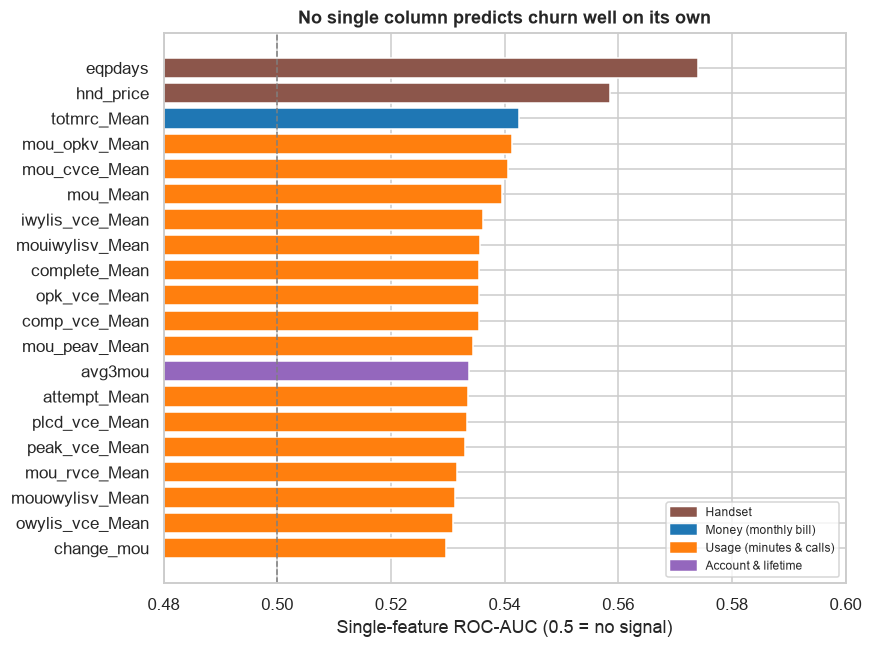

,auc,direction,family
eqpdays,0.574,higher → more churn,Handset
hnd_price,0.558,lower → more churn,Handset
totmrc_Mean,0.542,lower → more churn,Money (monthly bill)
mou_opkv_Mean,0.541,lower → more churn,Usage (minutes & calls)
mou_cvce_Mean,0.541,lower → more churn,Usage (minutes & calls)
mou_Mean,0.539,lower → more churn,Usage (minutes & calls)
iwylis_vce_Mean,0.536,lower → more churn,Usage (minutes & calls)
mouiwylisv_Mean,0.536,lower → more churn,Usage (minutes & calls)
complete_Mean,0.536,lower → more churn,Usage (minutes & calls)
opk_vce_Mean,0.536,lower → more churn,Usage (minutes & calls)


In [26]:
uni = {}
for c in num_cols:
    s = df[[c, "churn"]].dropna()
    a = roc_auc_score(s.churn, s[c])
    uni[c] = {"auc": max(a, 1 - a), "direction": "higher → more churn" if a > .5 else "lower → more churn",
              "family": col2fam[c]}
uni = pd.DataFrame(uni).T.sort_values("auc", ascending=False)
uni["auc"] = uni["auc"].astype(float)

top20 = uni.head(20)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top20.index[::-1], top20.auc[::-1], color=[fam_palette[f] for f in top20.family[::-1]])
ax.axvline(.5, color=BASE, ls="--", lw=1)
ax.set_xlim(.48, .6); ax.set_xlabel("Single-feature ROC-AUC (0.5 = no signal)")
ax.set_title("No single column predicts churn well on its own")
fams = list(dict.fromkeys(top20.family))
ax.legend([plt.Rectangle((0, 0), 1, 1, color=fam_palette[f]) for f in fams], fams, fontsize=8, loc="lower right")
save(fig, "08_univariate_auc"); plt.show()
uni.head(10).round(3)

**What we see:**
- The best single column is **`eqpdays` (phone age), with AUC ≈ 0.57**, followed by handset price, plan fee and usage-volume columns.
- **No column exceeds ~0.6, so there is no sign of leakage.** All columns appear safe to use.
- Note that `months` ranks low here, despite the dramatic cliff in 7.1. Its effect is **non-monotonic** (low, then spike, then medium), and a single-number AUC cannot capture that shape. A tree-based model can.

**Meaning for modelling:** churn here is **multi-causal**: many weak signals, none decisive. We therefore need a **multivariate, non-linear model** (gradient boosting such as XGBoost/LightGBM) and should compare it with a simple logistic-regression baseline. Realistic expectations: an AUC of about **0.65–0.70**. We should set that expectation with the client up front. What makes the model useful is not perfection but **ranking**: concentrating churners in the top 10–20% of the list, so the retention budget is spent where it matters.

## 9. Value at risk

**Why:** executives think in money, not churn rates. How much of Company A's monthly revenue sits with customers who left?

In [27]:
rev = df.rev_Mean.fillna(0)
churn_rev = rev[df.churn == 1].sum()
print(f"Monthly revenue from churners: ${churn_rev:,.0f} of ${rev.sum():,.0f} ({churn_rev / rev.sum():.1%})")
print(f"Median monthly bill  -> churners ${df.loc[df.churn == 1, 'rev_Mean'].median():.2f} | "
      f"stayers ${df.loc[df.churn == 0, 'rev_Mean'].median():.2f}")
print(f"Median lifetime value so far -> churners ${df.loc[df.churn == 1, 'totrev'].median():,.0f} | "
      f"stayers ${df.loc[df.churn == 0, 'totrev'].median():,.0f}")

# Revenue concentration: what share of revenue comes from the top X% of customers?
r = rev.sort_values(ascending=False).cumsum() / rev.sum()
for q in (.1, .2, .5):
    print(f"Top {q:.0%} of customers by bill generate {r.iloc[int(len(r) * q) - 1]:.0%} of revenue")

Monthly revenue from churners: $2,870,796 of $5,851,035 (49.1%)
Median monthly bill  -> churners $47.49 | stayers $48.88
Median lifetime value so far -> churners $824 | stayers $784
Top 10% of customers by bill generate 27% of revenue
Top 20% of customers by bill generate 42% of revenue
Top 50% of customers by bill generate 73% of revenue


**What we see:**
- In this (balanced) sample, churners account for about **49% of monthly revenue**, matching their share of customers. Churners and stayers have similar bills (median about \$47 vs \$49).
- Revenue is concentrated. The **top 20% of customers generate roughly 40% of revenue**.

**Meaning:**
- Because risk is spread evenly across bill sizes (7.5) while revenue is concentrated, **value-weighted targeting** (probability × revenue) can protect far more revenue per offer than targeting by risk alone. This is a key argument for the proposal.
- **Reminder:** the 49% figure is inflated by the 50/50 sampling. For the business case, recompute value at risk using a realistic monthly churn rate from market sources (e.g. US wireless postpaid churn of ~1–2% per month), and state the assumption on the slide.

## 10. Summary

### 10.1 Key findings

| # | Finding | Evidence | Can Company A act on it? |
|---|---|---|---|
| 1 | **Contract cliff:** churn nearly doubles at month 11–12 | 29–40% at months 7–10, then 65% / 62% at months 11 / 12 | **Yes:** renewal offer before month 10 |
| 2 | **Ageing phones drive churn**, independent of tenure | 42% (< 6 mo) → 58% (> 2 yr); same pattern within tenure groups | **Yes:** targeted handset upgrade |
| 3 | **Cheap / basic / refurbished phones** churn more | < \$40 phone 57% vs > \$150 41% | **Yes:** upgrade offer |
| 4 | **Usage fades before leaving** | usage fell > 200 min: 55%; zero usage: ~80% | **Partly:** early-warning outreach |
| 5 | **Silent customers leave**, engaged ones stay | no care calls 52% vs > 3/mo 45% | **Partly:** proactive contact |
| 6 | **Dropped calls** raise churn moderately | worst 20%: 53% vs best 47% | Slowly (network) / goodwill credit |
| 7 | **Risk is flat across bill size**, revenue is concentrated | deciles 47–54%; top 20% = ~40% revenue | Targeting: rank by **expected revenue loss** |
| 8 | **Region varies** 46–57% | Northwest/Rocky Mountain highest | Pilot location |
| 9 | **No single strong predictor**, no leakage | best single AUC ≈ 0.57 | Need a multivariate model |

### 10.2 Hypotheses to carry into modelling and the proposal
- **H1:** customers approaching contract end (months 9–12) *and* holding a phone older than 1 year are the highest-value retention target.
- **H2:** a combined model will rank customers well enough that the top 20% of scores contain a churn rate far above the average, making targeted offers cost-effective.
- **H3:** ranking by *expected revenue loss* (probability × bill) protects more revenue per dollar of offer than ranking by probability alone.

### 10.3 Data-preparation decisions for the modelling notebook
1. Drop `Customer_ID` and `recv_sms_Mean` (no information), and `ethnic` (sensitive attribute; see 7.8).
2. Set negative `eqpdays`, `rev_Mean` and `totmrc_Mean` to missing.
3. Keep `NaN` for tree models (handled natively). Add a flag for "usage block missing" and for "zero usage".
4. Categorical columns: native categorical support or one-hot. `crclscod` → first letter. Treat `U` / missing as their own level.
5. Engineered features worth testing:
   - `contract_window` (months 10–12)
   - `eqp_to_tenure` = eqpdays ÷ (months × 30)
   - `drop_rate` = dropped ÷ attempted calls
   - `usage_trend` = mou_Mean ÷ avg6mou
   - `rev_per_line` = rev_Mean ÷ uniqsubs
6. Remove the near-duplicates for the logistic-regression baseline (keep one per group). For tree models, read importances by family.
7. Metrics: **ROC-AUC** (overall ranking quality), plus **churn rate and capture in the top 10/20%** (what the retention team experiences). Report accuracy too, because the classes are balanced.

### 10.4 Open questions and assumptions to state on the slides
- The sample is balanced at 50% churn, so impact figures must be **rescaled to a realistic base churn rate** using a cited market source.
- The data is voice-era, US-based (regions are US metro areas). Frame the market analysis accordingly.
- The meanings of the credit-class letters and two undocumented columns are assumptions.
- All findings are **correlations**. A pilot with a control group is needed to prove that offers *cause* customers to stay.